In [19]:
#Import all neccesary libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pickle
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

# KDEF -> FER2013  Cross-Dataset Generalization

The preprocessed KDEF data is loaded from `data/kdef_preprocessed.pkl`. The training and test images are concatlabels arenated to create the KDEF dataset used only for training in this cross-dataset experiment. The emotion label `afraid` is mapped to `fear` to maintain consistency with FER2013.

In [20]:
with open("data/kdef_preprocessed.pkl", "rb") as f:
    kdef_data = pickle.load(f)

X_kdef = np.concatenate([kdef_data['X_train_kdef'], kdef_data['X_test_kdef']], axis=0)
y_kdef = np.concatenate([kdef_data['y_train_kdef'], kdef_data['y_test_kdef']], axis=0)

print("KDEF images:", X_kdef.shape)
print("KDEF labels:", y_kdef.shape)
print("Unique emotions:", np.unique(y_kdef))



KDEF images: (980, 48, 48)
KDEF labels: (980,)
Unique emotions: ['afraid' 'angry' 'disgust' 'happy' 'neutral' 'sad' 'surprise']


Histogram of Oriented Gradients (HOG) features are extracted from the KDEF images. Each image is checked to ensure that it has dimensions of 48 × 48 pixels. Pixel values are normalized to the range [0, 1] when necessary.

In [21]:
y_kdef = np.array([
    "afraid" if str(label).lower() == "fear"
    else str(label).lower()
    for label in y_kdef
])

def extract_hog_features(images):
    features = []

    for img in images:
        img = np.asarray(img).squeeze()

        if img.shape != (48, 48):
            raise ValueError(f"Expected (48, 48), got {img.shape}")

        img = img.astype(np.float32)

        # Normalize images in the 0–255 range to 0–1
        if img.max() > 1.0:
            img /= 255.0

        feature = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )
        features.append(feature)

    return np.asarray(features, dtype=np.float32)


X_kdef_hog = extract_hog_features(X_kdef)

print("HOG feature shape:", X_kdef_hog.shape)
print("Labels:", np.unique(y_kdef))

HOG feature shape: (980, 900)
Labels: ['afraid' 'angry' 'disgust' 'happy' 'neutral' 'sad' 'surprise']


Train the Random Forest classifier

In [22]:
rf_kdef_hog = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_kdef_hog.fit(X_kdef_hog, y_kdef)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",11
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

The FER2013 test file is loaded, and only the images labelled PrivateTest are retrived.

HOG features are then extracted using the same feature-extraction function and parameter settings used for KDEF, ensuring that both datasets are represented using the same feature format.

In [39]:
# Load FER2013 data and retain only PrivateTest rows
fer_df = pd.read_csv("data/fer2013_test.csv")
fer_df = fer_df[fer_df["Usage"] == "PrivateTest"].copy()

# FER2013 numeric label mapping
fer_label_map = {
    0: "angry",
    1: "disgust",
    2: "fear",
    3: "happy",
    4: "sad",
    5: "surprise",
    6: "neutral"
}

# Convert pixel strings into 48x48 grayscale images
X_fer_test = np.stack([
    np.fromstring(pixel_string, sep=" ", dtype=np.uint8).reshape(48, 48)
    for pixel_string in fer_df["pixels"]
])

# Convert numeric labels to emotion names
y_fer_test = fer_df["emotion"].map(fer_label_map).to_numpy()

y_fer_test = np.array([
        "afraid" if str(label).lower() == "fear"
        else str(label).lower()
        for label in y_fer_test
    ])

print("FER PrivateTest images:", X_fer_test.shape)
print("FER labels:", y_fer_test.shape)
print("Unique emotions:", np.unique(y_fer_test))
print("Missing labels:", pd.isna(y_fer_test).sum())

FER PrivateTest images: (3589, 48, 48)
FER labels: (3589,)
Unique emotions: ['afraid' 'angry' 'disgust' 'happy' 'neutral' 'sad' 'surprise']
Missing labels: 0


In [40]:
X_fer_hog = extract_hog_features(X_fer_test)

print("KDEF HOG shape:", X_kdef_hog.shape)
print("FER HOG shape:", X_fer_hog.shape)

KDEF HOG shape: (980, 900)
FER HOG shape: (3589, 900)


Cross-Dataset Generalization Results
------------------------------------
Accuracy: 0.21900250766230148
Balanced accuracy: 0.2028127293358761
Macro F1: 0.16634373657617316

Classification Report:
              precision    recall  f1-score   support

       angry       0.20      0.05      0.08       491
     disgust       0.04      0.07      0.05        55
      afraid       0.15      0.21      0.17       528
       happy       0.39      0.33      0.36       879
         sad       0.19      0.22      0.20       594
    surprise       0.19      0.53      0.28       416
     neutral       0.32      0.01      0.02       626

    accuracy                           0.22      3589
   macro avg       0.21      0.20      0.17      3589
weighted avg       0.25      0.22      0.19      3589



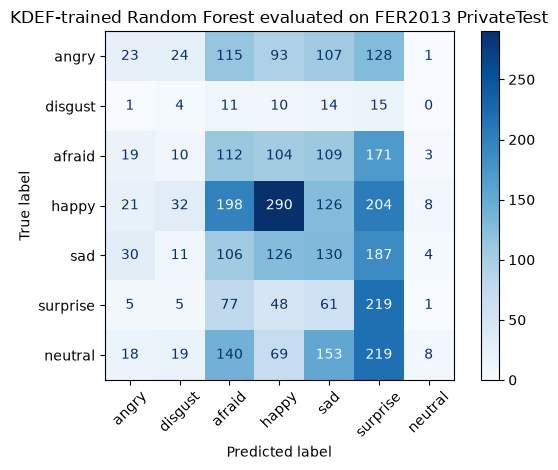

In [42]:
# Predict using the model trained on KDEF only
y_fer_pred = rf_kdef_hog.predict(X_fer_hog)

print("Cross-Dataset Generalization Results")
print("------------------------------------")
print("Accuracy:", accuracy_score(y_fer_test, y_fer_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_fer_test, y_fer_pred))
print("Macro F1:", f1_score(y_fer_test, y_fer_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_fer_test,
    y_fer_pred,
    labels=["angry", "disgust", "afraid", "happy", "sad", "surprise", "neutral"],
    zero_division=0
))

labels = ["angry", "disgust", "afraid", "happy", "sad", "surprise", "neutral"]

cm = confusion_matrix(y_fer_test, y_fer_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("KDEF-trained Random Forest evaluated on FER2013 PrivateTest")
plt.tight_layout()
plt.show()

The KDEF-trained Random Forest predicts emotion labels for the FER2013 PrivateTest images. Accuracy, balanced accuracy, and macro F1-score are calculated to assess classification performance. A classification report provides precision, recall, and F1-score for each emotion, while the confusion matrix visualizes the emotions that are frequently misclassified.

Results:-

- Accuracy: 21.79%
- Balanced accuracy: 20.17%
- Macro F1-score: 16.52%

Conclusion

The results indicate limited generalization from KDEF to FER2013. Differences in image characteristics, facial-expression presentation, and class distributions may affect the HOG features and the classifier's predictions. The low macro F1-score suggests poor overall performance across the emotion categories.

This experiment demonstrates that a model trained on one dataset may perform substantially worse when evaluated on a different dataset, even when both datasets contain the same emotion categories and use the same feature-extraction procedure.

# FER2013 -> KDEF Cross-Dataset Generalization

A Random Forest classifier is trained on the FER2013 training dataset and evaluated on the held-out KDEF test dataset. The objective is to examine how well a model trained on one facial-expression dataset generalizes to a different dataset without additional training.

The FER2013 training data is loaded from `data/fer2013_train.csv`, and only rows labelled Training are retained.

In [26]:
# Load FER2013 data and retain only Training rows
fer_df = pd.read_csv("data/fer2013_train.csv")
fer_df = fer_df[fer_df["Usage"] == "Training"].copy()

# FER2013 numeric label mapping
fer_label_map = {
    0: "angry",
    1: "disgust",
    2: "afraid",
    3: "happy",
    4: "sad",
    5: "surprise",
    6: "neutral"
}

# Convert pixel strings into 48x48 grayscale images
X_fer_train = np.stack([
    np.fromstring(pixel_string, sep=" ", dtype=np.uint8).reshape(48, 48)
    for pixel_string in fer_df["pixels"]
])

# Convert numeric labels to emotion names
y_fer_train = fer_df["emotion"].map(fer_label_map).to_numpy()


print("FER Train images:", X_fer_train.shape)
print("FER labels:", y_fer_train.shape)
print("Unique emotions:", np.unique(y_fer_train))
print("Missing labels:", pd.isna(y_fer_train).sum())

FER Train images: (28709, 48, 48)
FER labels: (28709,)
Unique emotions: ['afraid' 'angry' 'disgust' 'happy' 'neutral' 'sad' 'surprise']
Missing labels: 0


In [27]:
X_fer_train_hog = extract_hog_features(X_fer_train)

print("FER HOG features:", X_fer_train_hog.shape)

FER HOG features: (28709, 900)


The preprocessed KDEF test images and their labels are loaded from `kdef_data`. These images are not used to train the FER2013 model. HOG features are extracted from the KDEF test images using the same feature-extraction settings.

For consistent evaluation, the KDEF label afraid must be mapped to fear, matching the FER2013 label categories before calculating the metrics.

In [28]:
X_kdef_test = kdef_data['X_test_kdef']
y_kdef_test = np.array(["fear" if l == "afraid" else l for l in kdef_data['y_test_kdef']])

print("KDEF images:", X_kdef_test.shape)
print("KDEF labels:", y_kdef_test.shape)
print("Unique emotions:", np.unique(y_kdef))

KDEF images: (196, 48, 48)
KDEF labels: (196,)
Unique emotions: ['afraid' 'angry' 'disgust' 'happy' 'neutral' 'sad' 'surprise']


In [29]:
rf_fer_hog = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_fer_hog.fit(X_fer_train_hog, y_fer_train)

print("Random Forest trained on fer2013.")

Random Forest trained on fer2013.


In [30]:
X_kdef_test_hog = extract_hog_features(X_kdef_test)

Cross-Dataset Generalization Results
------------------------------------
Accuracy: 0.19387755102040816
Balanced accuracy: 0.19387755102040813
Macro F1: 0.09500281315533732

Classification Report:
              precision    recall  f1-score   support

       angry       0.00      0.00      0.00        28
     disgust       0.00      0.00      0.00        28
      afraid       0.00      0.00      0.00         0
       happy       0.23      1.00      0.37        28
         sad       0.00      0.00      0.00        28
    surprise       1.00      0.07      0.13        28
     neutral       0.11      0.29      0.16        28

   micro avg       0.19      0.23      0.21       168
   macro avg       0.19      0.19      0.10       168
weighted avg       0.22      0.23      0.11       168



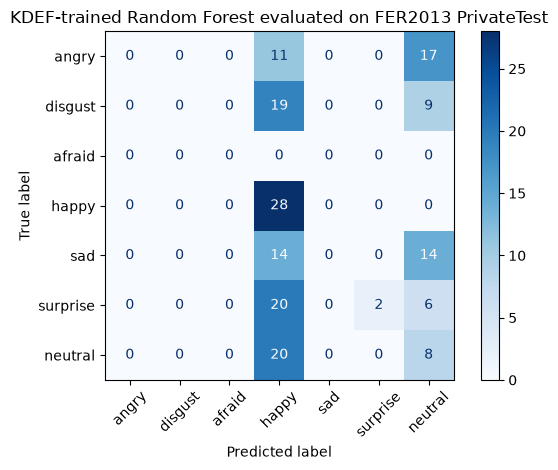

In [43]:
# Predict using the model trained on KDEF only
y_kdef_pred = rf_fer_hog.predict(X_kdef_test_hog)

print("Cross-Dataset Generalization Results")
print("------------------------------------")
print("Accuracy:", accuracy_score(y_kdef_test, y_kdef_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_kdef_test, y_kdef_pred))
print("Macro F1:", f1_score(y_kdef_test, y_kdef_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_kdef_test, y_kdef_pred,
    labels=["angry", "disgust", "afraid", "happy", "sad", "surprise", "neutral"],
    zero_division=0
))

labels = ["angry", "disgust", "afraid", "happy", "sad", "surprise", "neutral"]

cm = confusion_matrix(y_kdef_test, y_kdef_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("KDEF-trained Random Forest evaluated on FER2013 PrivateTest")
plt.tight_layout()
plt.show()

The FER2013-trained Random Forest predicts emotion labels for the held-out KDEF test images. Accuracy, balanced accuracy, and macro F1-score are calculated to assess classification performance.

Results

- Accuracy: 19.39%

- Balanced accuracy: 19.39%

- Macro F1-score: 9.50%

Conclusion

The results indicate limited generalization from FER2013 to KDEF. Differences in image characteristics, facial-expression presentation, and class distributions may affect the HOG features and the classifier's predictions. The low macro F1-score suggests poor overall performance across the emotion categories.

This experiment demonstrates that a model trained on one dataset may perform substantially worse when evaluated on a different dataset, even when both datasets contain the same emotion categories and use the same feature-extraction procedure.